In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

#dataset na het opschonen van missing values inlezen
df = pd.read_csv('Leesmateriaal_DU.csv')
df = df.convert_dtypes()


In [2]:
# Vaste volgorde van de niveaus voor alle grafieken
niveau_volgorde = ["2F", "2F-3F", "3F", "3F+"]

# Teksten met onbekend niveau laten we weg bij vergelijkingen per niveau
bekend = df[df["Niveau"] != "Onbekend"]

Niveau             2F  2F-3F  3F  3F+
genre                                
Fictie             81      5  36   10
Fictie / Roman     18      4   4    0
Fictie / Thriller  20      2  11    0
Informatief         5      5  18   11
Poëzie              2      5  10    4
Roman               1      0   0    1
Thriller            3      0   1    0


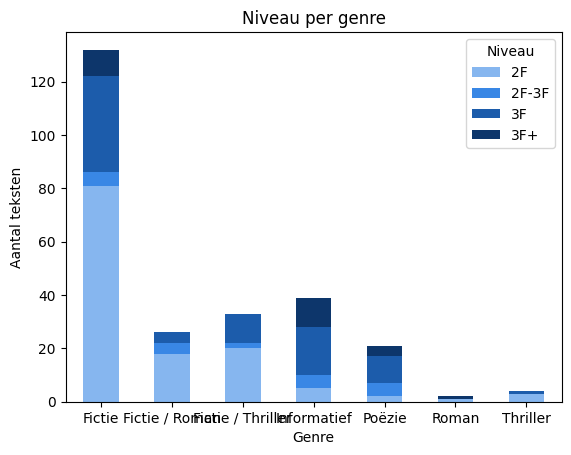

In [3]:
# Aantal teksten per combinatie van genre en niveau
kruis = pd.crosstab(bekend["genre"], bekend["Niveau"])[niveau_volgorde]
print(kruis)

kruis.plot(kind="bar", stacked=True, color=["#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])
plt.title("Niveau per genre")
plt.xlabel("Genre")
plt.ylabel("Aantal teksten")
plt.xticks(rotation=0)
plt.show()

                   count   mean    std    min    25%    50%    75%    max
genre                                                                    
Fictie             132.0  457.0  221.0  100.0  247.0  436.0  632.0  946.0
Fictie / Roman      26.0  392.0  234.0  114.0  247.0  286.0  508.0  894.0
Fictie / Thriller   33.0  478.0  203.0  143.0  302.0  468.0  618.0  899.0
Informatief         39.0   13.0    5.0    5.0   10.0   14.0   16.0   20.0
Poëzie              21.0  478.0  230.0  177.0  330.0  432.0  685.0  839.0
Roman                2.0  484.0  513.0  122.0  303.0  484.0  666.0  847.0
Thriller             4.0  444.0  110.0  346.0  356.0  431.0  520.0  570.0


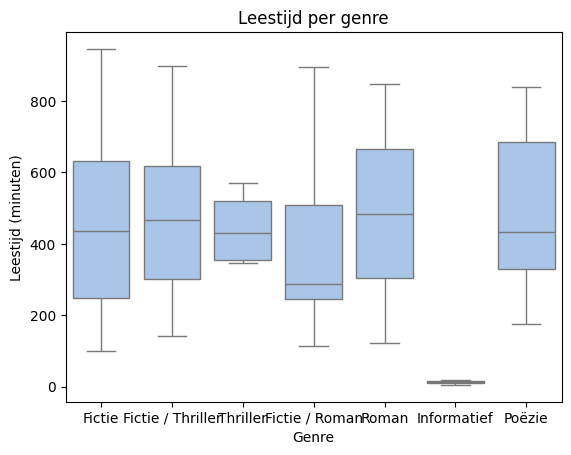

In [4]:
# Leestijd per genre
print(df.groupby("genre")["geschatte_leestijd_min"].describe().round(0))

sns.boxplot(data=df, x="genre", y="geschatte_leestijd_min", color="#9ec5f4")
plt.title("Leestijd per genre")
plt.xlabel("Genre")
plt.ylabel("Leestijd (minuten)")
plt.show()

        count  mean  median
Niveau                     
2F        139  43.7    43.7
2F-3F      21  48.5    45.4
3F         88  46.8    46.3
3F+        29  49.3    47.5


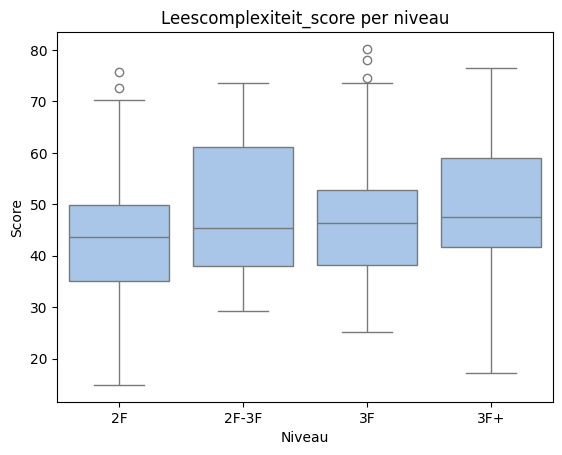

Kruskal-Wallis p = 0.083


In [5]:
# Gemiddelde en mediaan van de score per niveau
print(bekend.groupby("Niveau")["leescomplexiteit_score"].agg(["count", "mean", "median"]).reindex(niveau_volgorde).round(1))

sns.boxplot(data=bekend, x="Niveau", y="leescomplexiteit_score", order=niveau_volgorde, color="#9ec5f4")
plt.title("Leescomplexiteit_score per niveau")
plt.xlabel("Niveau")
plt.ylabel("Score")
plt.show()

# Toets: verschillen de niveaus?
groepen = [g["leescomplexiteit_score"] for _, g in bekend.groupby("Niveau")]
h, p = stats.kruskal(*groepen)
print("Kruskal-Wallis p =", round(p, 3))